# Langkah 12 Anggota A — Mini-eksperimen Deep Learning: MLP pada Fitur Lengkap vs Terpilih

**Tugas (Rencana Kerja, mini-eksperimen mingguan Anggota A, Minggu 12):** latih MLP kecil (2 hidden layer) pada **semua fitur vs fitur terpilih**, dengan split dan metrik yang sama, lalu serahkan hasilnya ke Anggota C untuk tabel benchmark (tabel ketergantungan no. 6, A → C).

**Pertanyaan yang dijawab:** apakah model yang lebih fleksibel (jaringan saraf) juga mendapat manfaat dari seleksi fitur, dan apakah hasilnya konsisten dengan SVM?

**Desain**

| Komponen | Pilihan | Alasan |
| --- | --- | --- |
| Model | `MLPClassifier`, 2 hidden layer, aktivasi ReLU, optimizer Adam, *early stopping* | Sesuai Rencana Kerja; tersedia di scikit-learn, jadi tidak perlu library tambahan |
| Subset fitur | Semua 90 fitur, subset SA-52 milik B, top-52 MI (langkah 10) | Fitur lengkap vs dua cara seleksi dengan k yang sama |
| Data | `features_peak.csv`; train aktor 1–16, validation aktor 17–20 | Versi terpilih di baseline B dan split yang sama |
| Tuning | `GridSearchCV` + `GroupKFold(4)` per aktor, hanya di train | Protokol yang sama seperti baseline B |
| Grid | Ukuran layer {(64, 32), (128, 64), (256, 128)} × alpha {0,001; 0,01; 0,1; 1; 3} | Kecil dan cepat; alpha = regularisasi L2 untuk mencegah overfitting |
| Penilaian | Macro F1 validation, rata-rata ± simpangan baku dari 5 seed | MLP sensitif terhadap inisialisasi acak; satu seed tidak cukup |
| Pembanding | SVM RBF (C = 1, gamma = scale), classifier yang dipakai B di dalam SA | Supaya MLP bisa dibandingkan dengan model utama |
| Model final | Dilatih ulang di train + validation (aktor 1–20) dengan parameter terbaik | Sesuai aturan model final di Rencana Kerja; **C yang mengevaluasinya di test, sekali** |

**Input dan output**

| Jenis | Lokasi (di `MyDrive/project07/`) | Keterangan |
| --- | --- | --- |
| Input | `data/features/features_peak.csv`, `feature_names.csv`, `data/splits.json` | Langkah 5 dan 7 |
| Input | `data/analysis/mi_topk_peak.json` | Langkah 10 (jalankan dulu) |
| Input | `progres_anggota_b/results/sa_main_results.json` | Subset SA-52 milik B |
| Output | `results/mlp_results.json`, `results/mlp_summary.csv` | Hasil untuk tabel benchmark C |
| Output | `models/mlp_full90.joblib`, `mlp_sa52.joblib`, `mlp_mi52.joblib` | Model final untuk dievaluasi C di test |
| Output | `figures/mlp/` | 2 grafik + `mlp_summary.txt` |
| Output | `docs/README_langkah12_mlp.md` | Dokumentasi standar |

**Aturan data:** data test (aktor 21–24) tidak disentuh. **Perkiraan waktu:** 2–5 menit.

## Sel 1 — Persiapan dan cek prasyarat

In [2]:
import os
import sys
import json
import time
import hashlib
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.metrics import f1_score, balanced_accuracy_score, accuracy_score

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_DIR = '/content/drive/MyDrive/project07'
except ImportError:
    BASE_DIR = os.path.abspath('project07')

DATA_DIR = os.path.join(BASE_DIR, 'data')
FEAT_DIR = os.path.join(DATA_DIR, 'features')
AN_DIR = os.path.join(DATA_DIR, 'analysis')
SRC_DIR = os.path.join(BASE_DIR, 'src')
RES_DIR = os.path.join(BASE_DIR, 'results')
MODEL_DIR = os.path.join(BASE_DIR, 'models')
FIG_DIR = os.path.join(BASE_DIR, 'figures', 'mlp')
DOC_DIR = os.path.join(BASE_DIR, 'docs')
CONFIG_PATH = os.path.join(BASE_DIR, 'config.json')
for d in [RES_DIR, MODEL_DIR, FIG_DIR, DOC_DIR]:
    os.makedirs(d, exist_ok=True)

SA_PATHS = [os.path.join(BASE_DIR, 'progres_anggota_b', 'results', 'sa_main_results.json'),
            os.path.join(BASE_DIR, 'results', 'sa_main_results.json')]
SA_PATH = next((p for p in SA_PATHS if os.path.exists(p)), None)
MI_PATH = os.path.join(AN_DIR, 'mi_topk_peak.json')
wajib = [CONFIG_PATH, os.path.join(FEAT_DIR, 'features_peak.csv'), os.path.join(FEAT_DIR, 'feature_names.csv'),
         os.path.join(DATA_DIR, 'splits.json'), os.path.join(SRC_DIR, 'data_splits.py'), MI_PATH]
hilang = [p for p in wajib if not os.path.exists(p)]
if hilang:
    raise FileNotFoundError('Prasyarat tidak ditemukan (jalankan langkah 10 dulu untuk mi_topk_peak.json):\n' + '\n'.join(hilang))
if SA_PATH is None:
    raise FileNotFoundError('sa_main_results.json milik Anggota B tidak ditemukan di: ' + ', '.join(SA_PATHS))

if SRC_DIR not in sys.path:
    sys.path.insert(0, SRC_DIR)
import data_splits as ds

with open(CONFIG_PATH, encoding='utf-8') as f:
    CONFIG = json.load(f)
F = list(pd.read_csv(os.path.join(FEAT_DIR, 'feature_names.csv'))['name'])
EMOTIONS = ['neutral', 'calm', 'happy', 'sad', 'angry', 'fearful', 'disgust', 'surprised']
ENC = {e: i for i, e in enumerate(EMOTIONS)}   # label diubah ke angka 0-7 (lihat catatan di Sel 3)

S = ds.load_splits(BASE_DIR)
tab = pd.read_csv(os.path.join(FEAT_DIR, 'features_peak.csv'))
tr, va, _ = ds.split_frames(tab, S)                 # test sengaja dibuang
X_tr, y_tr, g_tr = tr[F].to_numpy(float), tr['emotion'].map(ENC).to_numpy(), tr['actor'].to_numpy()
X_va, y_va = va[F].to_numpy(float), va['emotion'].map(ENC).to_numpy()
ys_tr, ys_va = tr['emotion'].to_numpy(), va['emotion'].to_numpy()   # label teks untuk SVM (sama seperti protokol B)

with open(SA_PATH, encoding='utf-8') as f:
    SA_IDX = sorted(int(i) for i in json.load(f)['selected_indices'])
with open(MI_PATH, encoding='utf-8') as f:
    MI = json.load(f)
MI_IDX = sorted(int(i) for i in MI['indices'])
SUBSETS = {'full90': ('Semua 90 fitur', list(range(len(F)))),
           f'sa{len(SA_IDX)}': (f'SA ({len(SA_IDX)} fitur)', SA_IDX),
           f'mi{len(MI_IDX)}': (f'MI top-{len(MI_IDX)}', MI_IDX)}

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#52514e', 'axes.labelcolor': '#0b0b0b',
                     'xtick.color': '#52514e', 'ytick.color': '#52514e',
                     'axes.titlecolor': '#0b0b0b', 'font.size': 10})

if sklearn.__version__ != '1.6.1':
    print(f'[PERHATIAN] scikit-learn di sesi ini {sklearn.__version__}, sedangkan model Anggota B dan hasil acuan memakai 1.6.1.')
    print('            Agar angka sama, jalankan: !pip install -q scikit-learn==1.6.1  lalu Runtime > Restart session, dan ulangi dari Sel 1.')
print('BASE_DIR     :', BASE_DIR, '| scikit-learn', sklearn.__version__)
print('Train / val  :', len(tr), '/', len(va), 'baris')
for kunci, (nama, idx) in SUBSETS.items():
    print(f'  {kunci:<7} {nama:<16} {len(idx)} fitur')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
BASE_DIR     : /content/drive/MyDrive/project07 | scikit-learn 1.6.1
Train / val  : 960 / 240 baris
  full90  Semua 90 fitur   90 fitur
  sa52    SA (52 fitur)    52 fitur
  mi52    MI top-52        52 fitur


## Sel 2 — Parameter dan `config.json`

In [3]:
GRID = {'clf__hidden_layer_sizes': [(64, 32), (128, 64), (256, 128)],
        'clf__alpha': [0.001, 0.01, 0.1, 1.0, 3.0]}
MLP_FIXED = {'activation': 'relu', 'solver': 'adam', 'learning_rate_init': 0.001, 'max_iter': 1000,
             'early_stopping': True, 'validation_fraction': 0.15, 'n_iter_no_change': 20}
SEEDS = [0, 1, 2, 3, 4]
SVM_REF = {'kernel': 'rbf', 'C': 1.0, 'gamma': 'scale', 'class_weight': 'balanced'}

MLP_CONFIG = {'grid': {k: [list(v) if isinstance(v, tuple) else v for v in vals] for k, vals in GRID.items()},
              'fixed': MLP_FIXED, 'seeds': SEEDS, 'cv': 'GroupKFold(4) per aktor di train',
              'version': 'peak', 'subsets': {k: len(v[1]) for k, v in SUBSETS.items()},
              'svm_reference': SVM_REF}
MLP_HASH = hashlib.md5(json.dumps({**MLP_CONFIG, 'features': CONFIG['features']['config_hash'],
                                   'sa': SA_IDX, 'mi': MI_IDX}, sort_keys=True, default=str).encode()).hexdigest()[:10]
CONFIG['mlp'] = {**MLP_CONFIG, 'features_hash': CONFIG['features']['config_hash'], 'sklearn': sklearn.__version__,
                 'version_tag': '1.0', 'config_hash': MLP_HASH, 'updated': datetime.now().strftime('%Y-%m-%d'),
                 'owner': 'Anggota A'}
with open(CONFIG_PATH, 'w', encoding='utf-8') as f:
    json.dump(CONFIG, f, indent=2, ensure_ascii=False)
print('config_hash mlp:', MLP_HASH)

def buat_mlp(hidden, alpha, seed):
    return Pipeline([('scaler', StandardScaler()),
                     ('clf', MLPClassifier(hidden_layer_sizes=tuple(hidden), alpha=alpha, random_state=seed, **MLP_FIXED))])

config_hash mlp: d03ab6d497


## Sel 3 — Tuning MLP di train (GroupKFold per aktor)

Untuk setiap subset, 15 kombinasi parameter dicoba dengan validasi silang 4 lipatan; setiap lipatan menyisihkan 4 aktor train. Data validation (aktor 17–20) belum dipakai di sini.

**Catatan teknis:** untuk MLP, label emosi diubah menjadi angka 0–7 (urutan `EMOTIONS`), karena di scikit-learn 1.6 `MLPClassifier` dengan `early_stopping=True` gagal jika label berupa teks. SVM pembanding tetap memakai label teks seperti protokol B, karena urutan kelas memengaruhi cara SVC memecah suara seri antar-kelas.

In [4]:
TUNING = {}
for kunci, (nama, idx) in SUBSETS.items():
    t0 = time.time()
    gs = GridSearchCV(buat_mlp((64, 32), 0.001, 0), GRID, scoring='f1_macro',
                      cv=GroupKFold(n_splits=4), n_jobs=-1, refit=False)
    gs.fit(X_tr[:, idx], y_tr, groups=g_tr)
    bp = gs.best_params_
    TUNING[kunci] = {'hidden': list(bp['clf__hidden_layer_sizes']), 'alpha': bp['clf__alpha'],
                     'cv_macro_f1': round(float(gs.best_score_), 4),
                     'cv_macro_f1_std': round(float(gs.cv_results_['std_test_score'][gs.best_index_]), 4),
                     'elapsed_s': round(time.time() - t0, 1)}
    print(f"{nama:<16} terbaik: layer {tuple(TUNING[kunci]['hidden'])}, alpha {TUNING[kunci]['alpha']} | "
          f"CV macro F1 {TUNING[kunci]['cv_macro_f1']:.4f} ± {TUNING[kunci]['cv_macro_f1_std']:.4f} | {TUNING[kunci]['elapsed_s']} s")

Semua 90 fitur   terbaik: layer (256, 128), alpha 1.0 | CV macro F1 0.4682 ± 0.0421 | 46.2 s
SA (52 fitur)    terbaik: layer (256, 128), alpha 0.01 | CV macro F1 0.4639 ± 0.0599 | 37.3 s
MI top-52        terbaik: layer (128, 64), alpha 0.01 | CV macro F1 0.4634 ± 0.0375 | 37.4 s


## Sel 4 — Penilaian di validation: MLP (5 seed) vs SVM

In [5]:
def skor(y_true, y_pred):
    return (f1_score(y_true, y_pred, average='macro'), balanced_accuracy_score(y_true, y_pred),
            accuracy_score(y_true, y_pred), f1_score(y_true, y_pred, average=None, labels=list(range(8))))

HASIL, PER_KELAS = {}, {}
for kunci, (nama, idx) in SUBSETS.items():
    tp = TUNING[kunci]
    f1s, uars, accs, kelas = [], [], [], []
    for s in SEEDS:
        m = buat_mlp(tp['hidden'], tp['alpha'], s).fit(X_tr[:, idx], y_tr)
        f1m, uar, acc, pk = skor(y_va, m.predict(X_va[:, idx]))
        f1s.append(f1m); uars.append(uar); accs.append(acc); kelas.append(pk)
    # SVM memakai label teks seperti protokol B: urutan kelas memengaruhi pemecahan suara seri di SVC
    svm = Pipeline([('scaler', StandardScaler()), ('clf', SVC(**SVM_REF, random_state=42))]).fit(X_tr[:, idx], ys_tr)
    pred_svm = svm.predict(X_va[:, idx])
    sf1, suar = f1_score(ys_va, pred_svm, average='macro'), balanced_accuracy_score(ys_va, pred_svm)
    HASIL[kunci] = {'subset': nama, 'k': len(idx),
                    'mlp_val_macro_f1_mean': round(float(np.mean(f1s)), 4), 'mlp_val_macro_f1_std': round(float(np.std(f1s)), 4),
                    'mlp_val_macro_f1_per_seed': [round(float(v), 4) for v in f1s],
                    'mlp_val_uar_mean': round(float(np.mean(uars)), 4), 'mlp_val_accuracy_mean': round(float(np.mean(accs)), 4),
                    'svm_val_macro_f1': round(float(sf1), 4), 'svm_val_uar': round(float(suar), 4),
                    **{f'tuning_{k}': v for k, v in tp.items()}}
    PER_KELAS[kunci] = np.mean(kelas, axis=0)

RINGKAS = pd.DataFrame([{'subset': h['subset'], 'k': h['k'],
                         'MLP layer': str(tuple(h['tuning_hidden'])), 'MLP alpha': h['tuning_alpha'],
                         'MLP CV F1 (train)': h['tuning_cv_macro_f1'],
                         'MLP val F1 (5 seed)': f"{h['mlp_val_macro_f1_mean']:.4f} ± {h['mlp_val_macro_f1_std']:.4f}",
                         'MLP val UAR': h['mlp_val_uar_mean'], 'SVM val F1': h['svm_val_macro_f1']}
                        for h in HASIL.values()])
display(RINGKAS)
PK = pd.DataFrame(PER_KELAS, index=EMOTIONS).round(3)
PK.columns = [SUBSETS[k][0] for k in PK.columns]
print('F1 per emosi di validation (MLP, rata-rata 5 seed):')
display(PK)

,subset,k,MLP layer,MLP alpha,MLP CV F1 (train),MLP val F1 (5 seed),MLP val UAR,SVM val F1
0,Semua 90 fitur,90,"(256, 128)",1.00,0.4682,0.4769 ± 0.0261,0.4719,0.5144
1,SA (52 fitur),52,"(256, 128)",0.01,0.4639,0.4771 ± 0.0244,0.4766,0.4995
2,MI top-52,52,"(128, 64)",0.01,0.4634,0.4523 ± 0.0284,0.4500,0.4658


F1 per emosi di validation (MLP, rata-rata 5 seed):


,Semua 90 fitur,SA (52 fitur),MI top-52
neutral,0.379,0.383,0.288
calm,0.556,0.557,0.548
happy,0.397,0.392,0.318
sad,0.298,0.308,0.366
angry,0.668,0.620,0.650
fearful,0.366,0.402,0.376
disgust,0.660,0.679,0.658
surprised,0.491,0.476,0.414


## Sel 5 — Model final untuk Anggota C

Sesuai aturan model final di Rencana Kerja, setiap MLP dilatih ulang di **train + validation** (aktor 1–20, 1.200 file) dengan parameter terbaik dari Sel 3 dan seed 0. File disimpan di `models/`. **Skor test tidak dihitung di sini**; C yang menghitungnya sekali dengan `evaluate()`.

Model mengeluarkan angka 0–7. Ubah ke nama emosi dengan `label_classes` di dalam bundle.

In [6]:
trva = pd.concat([tr, va], ignore_index=True)
X_trva, y_trva = trva[F].to_numpy(float), trva['emotion'].map(ENC).to_numpy()
MODEL_FILES = {}
for kunci, (nama, idx) in SUBSETS.items():
    tp = TUNING[kunci]
    m = buat_mlp(tp['hidden'], tp['alpha'], 0).fit(X_trva[:, idx], y_trva)
    bundle = {'pipeline': m, 'label_classes': EMOTIONS, 'normalization': 'peak',
              'selected_indices': idx, 'selected_feature_names': [F[i] for i in idx],
              'params': {'hidden_layer_sizes': tp['hidden'], 'alpha': tp['alpha'], **MLP_FIXED, 'random_state': 0},
              'trained_on': 'train + validation split utama (aktor 1-20, 1200 file)',
              'val_macro_f1_mean_5seed': HASIL[kunci]['mlp_val_macro_f1_mean'],
              'sklearn_version': sklearn.__version__, 'config_hash': MLP_HASH, 'owner': 'Anggota A',
              'note': 'Prediksi berupa angka 0-7; label = label_classes[prediksi]. Skor test dihitung Anggota C.'}
    path = os.path.join(MODEL_DIR, f'mlp_{kunci}.joblib')
    joblib.dump(bundle, path)
    MODEL_FILES[kunci] = os.path.relpath(path, BASE_DIR)
    print('Tersimpan:', MODEL_FILES[kunci])

hasil_json = {'created': datetime.now().strftime('%Y-%m-%d %H:%M'), 'owner': 'Anggota A', 'config_hash': MLP_HASH,
              'sklearn_version': sklearn.__version__, 'normalization': 'peak',
              'protocol': 'tuning GroupKFold(4) di train; val macro F1 rata-rata 5 seed; model final di train+val',
              'label_classes': EMOTIONS, 'results': HASIL, 'model_files': MODEL_FILES,
              'per_class_f1_val_mlp': {k: dict(zip(EMOTIONS, [round(float(v), 4) for v in PER_KELAS[k]])) for k in PER_KELAS}}
with open(os.path.join(RES_DIR, 'mlp_results.json'), 'w', encoding='utf-8') as f:
    json.dump(hasil_json, f, indent=2, ensure_ascii=False)
RINGKAS.to_csv(os.path.join(RES_DIR, 'mlp_summary.csv'), index=False)
print('Tersimpan: results/mlp_results.json, results/mlp_summary.csv')

Tersimpan: models/mlp_full90.joblib
Tersimpan: models/mlp_sa52.joblib
Tersimpan: models/mlp_mi52.joblib
Tersimpan: results/mlp_results.json, results/mlp_summary.csv


## Sel 6 — Verifikasi

In [7]:
laporan = []
def cek(nama, kondisi, detail=''):
    laporan.append(f"[{'OK' if kondisi else 'CEK'}] {nama}" + (f' — {detail}' if detail else ''))

cek('Tuning hanya memakai train (aktor 1-16, 960 baris)',
    sorted(int(a) for a in tr['actor'].unique()) == S['train'] and len(tr) == 960)
lipatan_ok = all(not set(g_tr[a]) & set(g_tr[b]) for a, b in GroupKFold(n_splits=4).split(X_tr, y_tr, g_tr))
cek('Setiap lipatan GroupKFold memisahkan aktor (tidak ada aktor di train dan validasi lipatan sekaligus)', lipatan_ok)
cek('Data test (aktor 21-24) tidak dipakai di tuning, penilaian, maupun model final',
    not set(S['test']) & set(trva['actor']))
cek('Model final dilatih di train + validation (aktor 1-20, 1.200 baris)',
    len(trva) == 1200 and sorted(int(a) for a in trva['actor'].unique()) == S['train'] + S['validation'])
cek('Setiap subset dinilai dengan 5 seed', all(len(h['mlp_val_macro_f1_per_seed']) == 5 for h in HASIL.values()))
muat_ok = True
for kunci, rel in MODEL_FILES.items():
    b = joblib.load(os.path.join(BASE_DIR, rel))
    p = b['pipeline'].predict(X_va[:5][:, b['selected_indices']])
    muat_ok &= len(p) == 5 and set(p) <= set(range(8)) and b['label_classes'] == EMOTIONS
cek('3 model final bisa dimuat ulang dan memprediksi label 0-7', muat_ok)
ref = {'full90': 0.5144, f'sa{len(SA_IDX)}': 0.4995}
svm_ok = all(abs(HASIL[k]['svm_val_macro_f1'] - v) < 0.005 for k, v in ref.items() if k in HASIL)
cek('SVM pembanding mereproduksi angka langkah 10 dan Anggota B', svm_ok,
    ', '.join(f"{k} {HASIL[k]['svm_val_macro_f1']:.4f}" for k in ref if k in HASIL))
for x in laporan:
    print(x)
n_ok = sum(x.startswith('[OK') for x in laporan)
print(f'\n{n_ok}/{len(laporan)} OK')

[OK] Tuning hanya memakai train (aktor 1-16, 960 baris)
[OK] Setiap lipatan GroupKFold memisahkan aktor (tidak ada aktor di train dan validasi lipatan sekaligus)
[OK] Data test (aktor 21-24) tidak dipakai di tuning, penilaian, maupun model final
[OK] Model final dilatih di train + validation (aktor 1-20, 1.200 baris)
[OK] Setiap subset dinilai dengan 5 seed
[OK] 3 model final bisa dimuat ulang dan memprediksi label 0-7
[OK] SVM pembanding mereproduksi angka langkah 10 dan Anggota B — full90 0.5144, sa52 0.4995

7/7 OK


## Sel 7 — Grafik

- `mlp_01`: macro F1 validation per subset, MLP (rata-rata 5 seed, garis = simpangan baku) vs SVM.
- `mlp_02`: F1 per emosi untuk MLP pada ketiga subset.

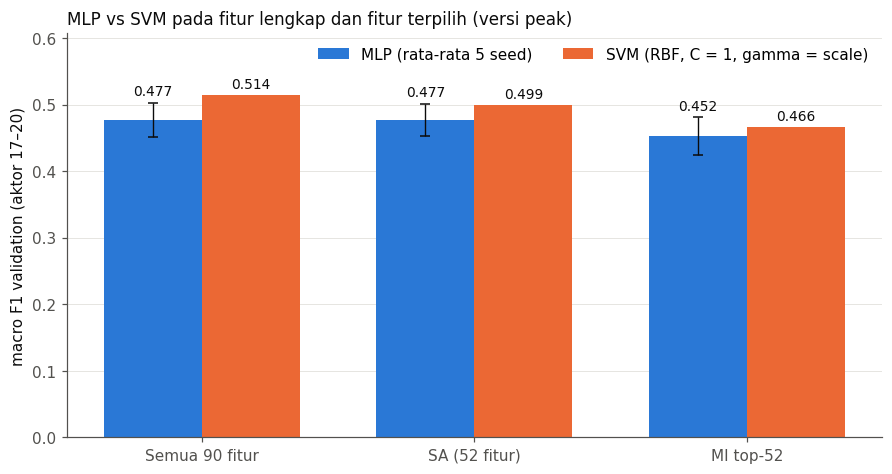

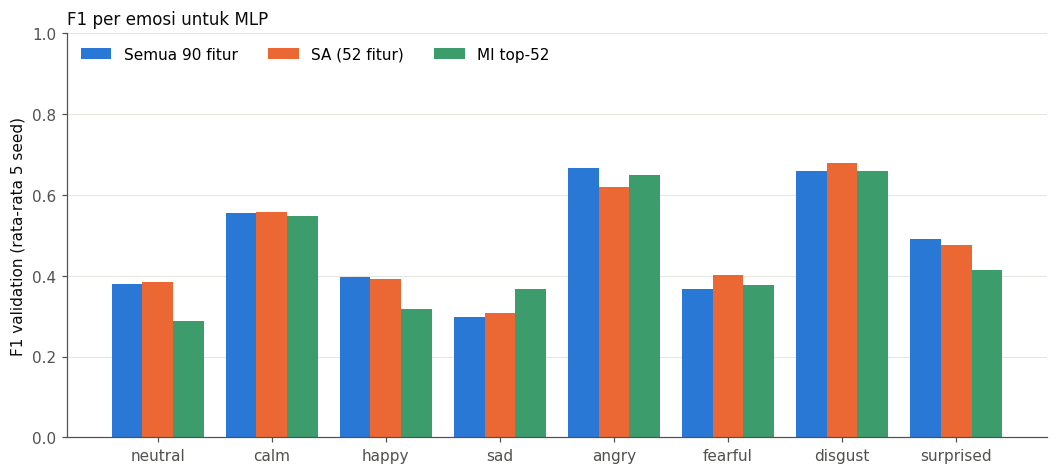

In [8]:
BIRU, ORANYE, HIJAU = '#2a78d6', '#eb6834', '#3c9c6c'
kunci_list = list(SUBSETS)
label_x = [SUBSETS[k][0] for k in kunci_list]
xg = np.arange(len(kunci_list))
w = 0.36
fig, ax = plt.subplots(figsize=(8, 4.2), layout='constrained')
mlp_m = [HASIL[k]['mlp_val_macro_f1_mean'] for k in kunci_list]
mlp_s = [HASIL[k]['mlp_val_macro_f1_std'] for k in kunci_list]
svm_v = [HASIL[k]['svm_val_macro_f1'] for k in kunci_list]
b1 = ax.bar(xg - w / 2, mlp_m, w, yerr=mlp_s, color=BIRU, label='MLP (rata-rata 5 seed)',
            error_kw={'ecolor': '#0b0b0b', 'elinewidth': 0.9, 'capsize': 3})
b2 = ax.bar(xg + w / 2, svm_v, w, color=ORANYE, label='SVM (RBF, C = 1, gamma = scale)')
for bars, vals, off in [(b1, mlp_m, mlp_s), (b2, svm_v, [0] * len(svm_v))]:
    for r, v, o in zip(bars, vals, off):
        ax.text(r.get_x() + r.get_width() / 2, v + o + 0.006, f'{v:.3f}', ha='center', va='bottom', fontsize=9, color='#0b0b0b')
ax.set_xticks(xg)
ax.set_xticklabels(label_x)
ax.set_ylim(0, max(max(mlp_m), max(svm_v)) * 1.18)
ax.set_ylabel('macro F1 validation (aktor 17–20)')
ax.grid(axis='y', color='#e4e3df', lw=0.6)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc='upper right', ncol=2)
ax.set_title('MLP vs SVM pada fitur lengkap dan fitur terpilih (versi peak)', loc='left', fontsize=11)
fig.savefig(os.path.join(FIG_DIR, 'mlp_01_mlp_vs_svm.png'))
plt.show()

fig, ax = plt.subplots(figsize=(9.5, 4.2), layout='constrained')
xe = np.arange(len(EMOTIONS))
w3 = 0.27
for j, (k, c) in enumerate(zip(kunci_list, [BIRU, ORANYE, HIJAU])):
    ax.bar(xe + (j - 1) * w3, PER_KELAS[k], w3, color=c, label=SUBSETS[k][0])
ax.set_xticks(xe)
ax.set_xticklabels(EMOTIONS)
ax.set_ylabel('F1 validation (rata-rata 5 seed)')
ax.set_ylim(0, 1)
ax.grid(axis='y', color='#e4e3df', lw=0.6)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=3, loc='upper left')
ax.set_title('F1 per emosi untuk MLP', loc='left', fontsize=11)
fig.savefig(os.path.join(FIG_DIR, 'mlp_02_f1_per_emosi.png'))
plt.show()

## Sel 8 — Ringkasan dan dokumentasi standar

In [9]:
tgl = datetime.now().strftime('%Y-%m-%d')
ringkas = [
    f'Ringkasan mini-eksperimen MLP (langkah 12, {tgl})',
    f"config_hash mlp: {MLP_HASH} | fitur: {CONFIG['features']['config_hash']} | scikit-learn {sklearn.__version__}",
    '',
    'Data: features_peak.csv; tuning di train (aktor 1-16), penilaian di validation (aktor 17-20); test tidak dipakai',
    'MLP: 2 hidden layer, ReLU, Adam, early stopping; tuning GroupKFold(4); 5 seed',
    '',
] + [f"{h['subset']:<16} k={h['k']:<3} MLP layer {tuple(h['tuning_hidden'])} alpha {h['tuning_alpha']} | "
     f"CV F1 {h['tuning_cv_macro_f1']:.4f} | val F1 {h['mlp_val_macro_f1_mean']:.4f} ± {h['mlp_val_macro_f1_std']:.4f} | "
     f"val UAR {h['mlp_val_uar_mean']:.4f} | SVM val F1 {h['svm_val_macro_f1']:.4f}" for h in HASIL.values()] + [
    '',
    'F1 per emosi (MLP, rata-rata 5 seed):',
    PK.to_string(),
    '',
    'Model final (train + validation): ' + ', '.join(MODEL_FILES.values()),
    '',
    f'Verifikasi: {n_ok}/{len(laporan)} OK',
] + ['  ' + x for x in laporan]
teks = '\n'.join(ringkas)
print(teks)
with open(os.path.join(FIG_DIR, 'mlp_summary.txt'), 'w', encoding='utf-8') as fh:
    fh.write(teks + '\n')

tabel = '\n'.join(f"| {h['subset']} | {h['k']} | {tuple(h['tuning_hidden'])}, {h['tuning_alpha']} | {h['tuning_cv_macro_f1']:.4f} | "
                  f"{h['mlp_val_macro_f1_mean']:.4f} ± {h['mlp_val_macro_f1_std']:.4f} | {h['mlp_val_uar_mean']:.4f} | {h['svm_val_macro_f1']:.4f} |"
                  for h in HASIL.values())
readme = f'''# Langkah 12 — Mini-eksperimen MLP: Fitur Lengkap vs Terpilih

Penanggung jawab: Anggota A · Versi: 1.0 · Dijalankan: {tgl} · config_hash: `{MLP_HASH}` (fitur `{CONFIG['features']['config_hash']}`)

## Tujuan

Mini-eksperimen deep learning Minggu 12 (Rencana Kerja; tabel ketergantungan no. 6, A → C): membandingkan MLP 2 hidden layer pada semua fitur vs fitur terpilih (SA dan MI), dengan split dan metrik yang sama.

## Protokol

- Data: `features_peak.csv`. Tuning di train (aktor 1–16) dengan `GridSearchCV` + `GroupKFold(4)` per aktor; grid ukuran layer {{(64, 32), (128, 64), (256, 128)}} × alpha {{0,001; 0,01; 0,1; 1; 3}}.
- MLP: ReLU, Adam (learning rate 0,001), early stopping (15% data latih, 20 epoch tanpa perbaikan), maksimum 1.000 epoch.
- Penilaian: macro F1 validation (aktor 17–20), rata-rata ± simpangan baku dari 5 seed. Pembanding: SVM RBF (C = 1, gamma = scale, class_weight = balanced).
- Model final: dilatih ulang di train + validation (aktor 1–20) dengan seed 0. Data test tidak dipakai.

## Hasil (validation)

| Subset | k | Layer, alpha | CV macro F1 train | Val macro F1 MLP (5 seed) | Val UAR MLP | Val macro F1 SVM |
| --- | --- | --- | --- | --- | --- | --- |
{tabel}

## Output

| File | Isi |
| --- | --- |
| `results/mlp_results.json` | Parameter, skor per seed, F1 per emosi, lokasi model |
| `results/mlp_summary.csv` | Tabel ringkas untuk benchmark C |
| `models/mlp_full90.joblib`, `mlp_sa{len(SA_IDX)}.joblib`, `mlp_mi{len(MI_IDX)}.joblib` | Bundle model final: `pipeline`, `label_classes`, `selected_indices`, `params`, `trained_on` |
| `figures/mlp/` | `mlp_01_mlp_vs_svm.png`, `mlp_02_f1_per_emosi.png`, `mlp_summary.txt` |

## Cara memakai (Anggota C)

```python
import joblib
b = joblib.load(BASE_DIR + '/models/mlp_sa{len(SA_IDX)}.joblib')
pred_kode = b['pipeline'].predict(X_test[:, b['selected_indices']])   # X_test dari features_peak.csv, 90 kolom fitur
pred_label = [b['label_classes'][i] for i in pred_kode]
```

## Verifikasi

{n_ok}/{len(laporan)} pemeriksaan OK.

''' + '\n'.join(f'- {x}' for x in laporan) + f'''

## Keterbatasan

- `MLPClassifier` tidak mendukung pembobotan kelas, sehingga kelas neutral (separuh jumlah kelas lain) tidak diberi bobot tambahan, berbeda dengan SVM (`class_weight='balanced'`).
- Early stopping menyisihkan 15% data latih secara acak (bukan per aktor), sehingga penghentiannya sedikit optimis.
- Dengan 960 data latih, MLP mudah overfitting; grid sengaja kecil dan memakai regularisasi alpha.
- Mini-eksperimen ini latihan pendukung, bukan metode utama proyek.

## Riwayat versi

| Versi | Tanggal | Perubahan |
| --- | --- | --- |
| 1.0 | {tgl} | Versi pertama |
'''
with open(os.path.join(DOC_DIR, 'README_langkah12_mlp.md'), 'w', encoding='utf-8') as fh:
    fh.write(readme)
print('\nTersimpan:', os.path.join(FIG_DIR, 'mlp_summary.txt'))
print('Tersimpan:', os.path.join(DOC_DIR, 'README_langkah12_mlp.md'))

Ringkasan mini-eksperimen MLP (langkah 12, 2026-11-24)
config_hash mlp: d03ab6d497 | fitur: 0c3114fc78 | scikit-learn 1.6.1

Data: features_peak.csv; tuning di train (aktor 1-16), penilaian di validation (aktor 17-20); test tidak dipakai
MLP: 2 hidden layer, ReLU, Adam, early stopping; tuning GroupKFold(4); 5 seed

Semua 90 fitur   k=90  MLP layer (256, 128) alpha 1.0 | CV F1 0.4682 | val F1 0.4769 ± 0.0261 | val UAR 0.4719 | SVM val F1 0.5144
SA (52 fitur)    k=52  MLP layer (256, 128) alpha 0.01 | CV F1 0.4639 | val F1 0.4771 ± 0.0244 | val UAR 0.4766 | SVM val F1 0.4995
MI top-52        k=52  MLP layer (128, 64) alpha 0.01 | CV F1 0.4634 | val F1 0.4523 ± 0.0284 | val UAR 0.4500 | SVM val F1 0.4658

F1 per emosi (MLP, rata-rata 5 seed):
           Semua 90 fitur  SA (52 fitur)  MI top-52
neutral             0.379          0.383      0.288
calm                0.556          0.557      0.548
happy               0.397          0.392      0.318
sad                 0.298          0.308  

## Selesai — yang dilakukan setelah notebook ini

1. Pastikan Sel 6 menampilkan semua **OK**.
2. Simpan notebook ke `project07/notebooks/Langkah12_AnggotaA_MLP.ipynb`.
3. Kirim ke Anggota C: `results/mlp_results.json`, `results/mlp_summary.csv`, dan ketiga file `models/mlp_*.joblib` untuk tabel benchmark dan evaluasi test (sekali).
4. Kirim ke saya isi `mlp_summary.txt` serta grafik `mlp_01` dan `mlp_02` untuk Log Kerja.